In [122]:
import numpy as np
import pandas as pd
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import optax
import unittest
from functools import partial 

import matplotlib.pyplot as plt

In [163]:
#@jax.jit
def loss_fn(z, inds, Sigma_tilde):
    # defines jax-numpy loss
    d = Sigma_tilde.shape[0]
    
    rows, cols = zip(*inds)
    rows, cols = np.array(rows), np.array(cols)
    Sigma_tilde_vec = Sigma_tilde[rows, cols]

    K_z = get_K(z, inds, d)
    
    log_det_term = logdet_psd(K_z)
    
    trace_term_old = jnp.trace(jnp.matmul(K_z, Sigma_tilde))
    trace_term = jnp.dot(z, Sigma_tilde_vec) 
    
    jax.debug.print("Sigma_tilde_vec: {}", Sigma_tilde_vec)
    jax.debug.print("K_z: {}", K_z)
    jax.debug.print("trace_term_old: {}", trace_term_old)
    jax.debug.print("trace_term: {}", trace_term)
    
    return -log_det_term + trace_term


def get_K(z, inds, d):
    """
    z: (jax array) vector supporting precision matrix estimate K(z)
    inds: (numpy array) list of the lower triangular nonzero element indices in Sigma_tilde
    d: dimension of Sigma_tilde
    """
    
    K = jnp.zeros((d, d))
    K = K.at[inds[:, 0], inds[:, 1]].set(z)
    
    return K


def get_observed_Sigma_entries(Sigma):

    d = Sigma.shape[0]

    diag_inds = [(i,i) for i in range(d)]   # assumed it's always observed
    tril_inds = get_strict_lower_triangle_nonzero(Sigma)
    triu_inds = [(j,i) for (i, j) in tril_inds]

    all_observed_inds = diag_inds + tril_inds + triu_inds

    print(np.array(all_observed_inds))
    
    return np.array(all_observed_inds)
    

def initialize_z(Sigma_tilde, inds):
    """
        Sigma_tilde: matrix of observed (privatized) covariance entries
    """

    d = Sigma_tilde.shape[0]

    z_init = []
    
    for (i,j) in inds:
        if i == j:
            z_init.append(max(0.01, 1./Sigma_tilde[i,j]))
        else:
            z_init.append(0)
        
    return jnp.array(z_init)

    
def optimize_lbfgs(Sigma_tilde, z, inds, max_iters=100, verbose=True):
    """
        Sigma_tilde: matrix of observed (privatized) covariance entries
        z: vector supporting K(z)
    """

    d = Sigma_tilde.shape[0]
    
    # Linesearch, comment/uncomment the desired one
    # linesearch = optax.scale_by_backtracking_linesearch(max_backtracking_steps=15)
    linesearch = optax.scale_by_zoom_linesearch(max_linesearch_steps=15)
    
    # Optimizer
    opt = optax.chain(
        optax.lbfgs(),
        # Compare with or without linesearch by commenting this line
        linesearch,
    )
    
    # Initialize
    state = opt.init(z)

    loss_fn_wrapper = partial(loss_fn, inds=inds, Sigma_tilde=Sigma_tilde)

    g_vals = []
    obj_vals = []
    
    # Run optimization
    for i in range(max_iters):
        v, g = jax.value_and_grad(loss_fn_wrapper)(z)
        obj_vals.append(v)
        
        updates, state = opt.update(g, state, z, value=v, grad=g, value_fn=loss_fn_wrapper)
        z = optax.apply_updates(z, updates)
        #z = jnp.add(z, updates)

        if verbose:
            print(f'iter: {i}, value:{v:.7e}')
            print(f"grad sum: {jnp.sum(jnp.abs(g))}")
            print(f"grad: {g}")
            print("z", z)
        
            K_z = get_K(z, inds, d)
            # if not is_positive_definite(K_z):
            #     print("NOT PD")
            #     #z = binary_search_pd_point(z, g)
            log_det_1 = logdet_psd(K_z)
            s, log_det_2 = jnp.linalg.slogdet(K_z)
            print("compare log det", log_det_1, log_det_2)
            print("\n")

        g_vals.append(jnp.sum(jnp.abs(g)))
        
    plt.plot(g_vals)
    plt.show()

    plt.plot(obj_vals)
    plt.show()
    
    return z


# helpers # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 

def is_positive_definite(M):
    return jnp.all(jnp.linalg.eigvalsh(M) > 0)

def get_strict_lower_triangle_nonzero(M):
    # lower triangle indices excluding the diagonal
    lower_triangle_indices = np.tril_indices(M.shape[0], k=-1)
    
    # nonzero elements in the lower triangle
    nonzero_mask = M[lower_triangle_indices] != 0
    filtered_indices = (lower_triangle_indices[0][nonzero_mask], lower_triangle_indices[1][nonzero_mask])
    
    # zip indices together into tuples
    indices_tuples = list(zip(filtered_indices[0].tolist(), filtered_indices[1].tolist()))
    
    return indices_tuples


@jax.jit
def logdet_psd(A):
    # Compute the Cholesky decomposition
    L = jnp.linalg.cholesky(A)

    # Check if any entry of the Cholesky factor is NaN
    is_nan = jnp.any(jnp.isnan(L))

    def nan_case(_):
        return -jnp.inf

    def valid_case(L):
        diag_L = jnp.diag(L)
        log_det = 2 * jnp.sum(jnp.log(diag_L))
        return log_det

    # Use jax.cond to choose between the cases
    return jax.lax.cond(is_nan, nan_case, valid_case, L)

def generate_multivariate_normal_data(n, d):
    mean = np.zeros(d)
    
    # Define a random positive definite covariance matrix (4x4)
    A = np.random.rand(n, d)
    covariance_matrix = np.dot(A.transpose(), A)
    
    # Generate the multivariate normal dataset
    dataset = np.random.multivariate_normal(mean, covariance_matrix, n)
    
    return dataset, covariance_matrix


def get_Sigma_tilde_d4(cov):
    M = np.zeros_like(cov)
    
    # copy diagonal
    np.fill_diagonal(M, np.diag(cov))
    
    # copy the [0,3] and [3,0] elements
    M[0, 3] = cov[0, 3]
    M[3, 0] = cov[3, 0]
    
    return M

def get_Sigma_tilde_d15(cov, off_diagonal_percentage=0.15):
    # by ChatGPT, review
    d = cov.shape[0]
    assert d == 15, "The function is designed for 15x15 matrices only."
    
    M = np.zeros_like(cov)
    
    # Copy diagonal
    np.fill_diagonal(M, np.diag(cov))
    
    # Number of off-diagonal entries to fill
    num_off_diagonal = int(off_diagonal_percentage * (d * (d - 1)) / 2)
    
    # Generate all possible off-diagonal indices
    off_diagonal_indices = [(i, j) for i in range(d) for j in range(i+1, d)]
    
    # Randomly select indices to fill
    selected_indices = np.random.choice(len(off_diagonal_indices), num_off_diagonal, replace=False)
    
    for idx in selected_indices:
        i, j = off_diagonal_indices[idx]
        M[i, j] = cov[i, j]
        M[j, i] = cov[j, i]
    
    return M

def is_positive_definite(K):
    return jnp.all(jnp.linalg.eigvalsh(K) > 0)

# tests # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 

class TestAuxiliaryFunctions(unittest.TestCase):
    def test_get_K(self):
        d = 3
        z = np.array([1., 2., 3., 4., 5.])
        # Updated indices to be within bounds for a 3x3 matrix
        inds = np.array([(0, 0), (1, 1), (2, 2), (1, 0), (2, 0)])
        
        K_result = get_K(z, inds, d)
        
        # Updated expected result matrix based on the new indices
        K_true = np.array([[1., 4., 5.],
                           [4., 2., 0.],
                           [5., 0., 3.]])
        
        assert np.allclose(K_result, K_true, atol=1e-10), "test_get_K failed"

    def test_initialize_z(self):
        Sigma_tilde = np.array([[1000., 0., 4.],
                               [0., 2., 0.],
                               [4., 0., 3.]])
        d = Sigma_tilde.shape[0]
        
        z_true = np.array([0.01, 1/2., 1/3., 0.])  
        z_init, inds_init = initialize_z(Sigma_tilde)

        for i in range(d):
            self.assertTrue(np.allclose(z_true, z_init, atol=1e-10)), "test_initialize_z failed"
            
unittest.main(argv=[''], verbosity=2, exit=False)

test_get_K (__main__.TestAuxiliaryFunctions) ... FAIL
test_initialize_z (__main__.TestAuxiliaryFunctions) ... ERROR

ERROR: test_initialize_z (__main__.TestAuxiliaryFunctions)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "/var/folders/_v/3q83tdz16dz82yk206z719v40000gn/T/ipykernel_96724/3634872461.py", line 250, in test_initialize_z
    z_init, inds_init = initialize_z(Sigma_tilde)
TypeError: initialize_z() missing 1 required positional argument: 'inds'

FAIL: test_get_K (__main__.TestAuxiliaryFunctions)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "/var/folders/_v/3q83tdz16dz82yk206z719v40000gn/T/ipykernel_96724/3634872461.py", line 241, in test_get_K
    assert np.allclose(K_result, K_true, atol=1e-10), "test_get_K failed"
AssertionError: test_get_K failed

----------------------------------------------------------------------
Ran 2 tests in 0.011s

F

In [ ]:
def run_adult_d4():

    adult_path = "/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult.csv"
    adult_data_d4 = pd.read_csv(adult_path)[["age", "workclass", "fnlwgt", "education"]]
    
    Sigma_true = adult_data_d4.cov().to_numpy()
    Prec_true = np.linalg.inv(Sigma_true)
    d = Sigma_true.shape[0]
    
    Sigma_tilde = get_Sigma_tilde_d4(Sigma_true)
    #Sigma_tilde = Sigma_tilde + np.random.normal(0, 0.01, size=Sigma_tilde.shape)
    Prec_tilde = np.linalg.inv(Sigma_tilde)
    inds = get_observed_Sigma_entries(Sigma_tilde)
    
    print(f"Sigma_true, {Sigma_true}")
    print(f"Prec_true, {Prec_true}")
    print(f"Sigma_tilde, {Sigma_tilde}")
    print(f"Prec_tilde, {Prec_tilde}")
    
    z_init = initialize_z(Sigma_tilde, inds)
    K_z_init = get_K(z_init,  inds, d)
    det_init = np.linalg.det(K_z_init)
    
    z_opt = optimize_lbfgs(Sigma_tilde, z_init, inds, max_iters=30)

    return z_opt

run_adult_d4()

[[0 0]
 [1 1]
 [2 2]
 [3 3]
 [3 0]
 [0 3]]
Sigma_true, [[26.54863137  1.12558197 -0.92236391 -0.29460695]
 [ 1.12558197  4.87413218 -0.10834532  0.20117863]
 [-0.92236391 -0.10834532  5.23528579 -0.19909199]
 [-0.29460695  0.20117863 -0.19909199 15.01169162]]
Prec_true, [[ 0.03827682 -0.00873201  0.00659933  0.00095573]
 [-0.00873201  0.20736026  0.00264208 -0.00291526]
 [ 0.00659933  0.00264208  0.19232948  0.00264487]
 [ 0.00095573 -0.00291526  0.00264487  0.06670765]]
Sigma_tilde, [[26.54863137  0.          0.         -0.29460695]
 [ 0.          4.87413218  0.          0.        ]
 [ 0.          0.          5.23528579  0.        ]
 [-0.29460695  0.          0.         15.01169162]]
Prec_tilde, [[0.03767493 0.         0.         0.00073938]
 [0.         0.20516473 0.         0.        ]
 [0.         0.         0.19101154 0.        ]
 [0.00073938 0.         0.         0.06662925]]
Sigma_tilde_vec: [26.54863137  4.87413218  5.23528579 15.01169162 -0.29460695 -0.29460695]
K_z: [[0.03766

In [129]:
K_z_opt = get_K(z_opt, inds_init, 4)

print("Sigma_true", Sigma_true)
print("Prec_true", Prec_true)
print("\n")
print("Sigma_tilde", Sigma_tilde)
print("Prec_tilde", Prec_tilde)
print("\n")
print("Sigma_opt", np.linalg.inv(K_z_opt))
print("Prec_opt", K_z_opt)

Sigma_true [[26.54863137  1.12558197 -0.92236391 -0.29460695]
 [ 1.12558197  4.87413218 -0.10834532  0.20117863]
 [-0.92236391 -0.10834532  5.23528579 -0.19909199]
 [-0.29460695  0.20117863 -0.19909199 15.01169162]]
Prec_true [[ 0.03827682 -0.00873201  0.00659933  0.00095573]
 [-0.00873201  0.20736026  0.00264208 -0.00291526]
 [ 0.00659933  0.00264208  0.19232948  0.00264487]
 [ 0.00095573 -0.00291526  0.00264487  0.06670765]]


Sigma_tilde [[26.54863137  0.          0.         -0.29460695]
 [ 0.          4.87413218  0.          0.        ]
 [ 0.          0.          5.23528579  0.        ]
 [-0.29460695  0.          0.         15.01169162]]
Prec_tilde [[0.03767493 0.         0.         0.00073938]
 [0.         0.20516473 0.         0.        ]
 [0.         0.         0.19101154 0.        ]
 [0.00073938 0.         0.         0.06662925]]


Sigma_opt [[26.54866594  0.          0.         -0.29460014]
 [ 0.          4.87413218  0.          0.        ]
 [ 0.          0.          5.2352857

Sigma_true, [[ 2.65486314e+01  1.12558197e+00 -9.22363910e-01 -2.94606949e-01
   4.19322938e-01 -1.33256091e+00  6.63984134e-01  8.12983385e-01
  -1.76772016e-01  2.13452425e-01  8.55234974e-01  7.30598679e-01
   1.48889862e+00 -8.44349487e-01  5.04702921e-01]
 [ 1.12558197e+00  4.87413218e+00 -1.08345319e-01  2.01178630e-01
   2.87266037e-01  8.13887018e-02  4.15097129e+00 -8.85899371e-02
   1.03851217e-01 -5.56511224e-02 -2.39842511e-02  1.54525415e-02
  -1.02551966e+00 -5.54074570e-01 -8.47154464e-03]
 [-9.22363910e-01 -1.08345319e-01  5.23528579e+00 -1.99091992e-01
  -2.30920697e-01  6.76691231e-02 -3.58955702e-04  3.84921372e-02
   2.91511141e-01  2.89196964e-02 -1.75814372e-02 -2.84153292e-02
  -1.24947412e-01  1.21550142e+00 -6.78373232e-03]
 [-2.94606949e-01  2.01178630e-01 -1.99091992e-01  1.50116916e+01
   3.58272695e+00 -1.47761344e-01 -7.98710468e-02 -6.61787769e-02
  -1.32112502e-01 -4.93214012e-02  2.49767190e-01  1.70815448e-01
   8.88022310e-01 -2.39913304e+00  1.323936

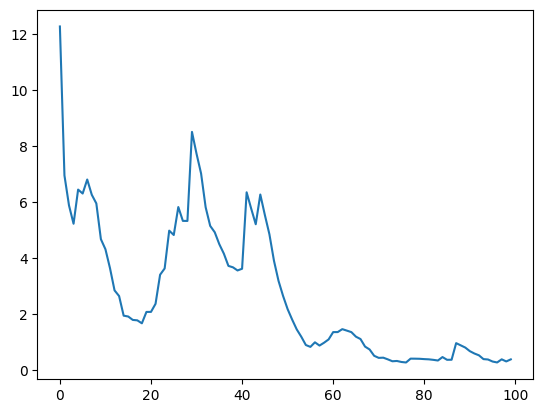

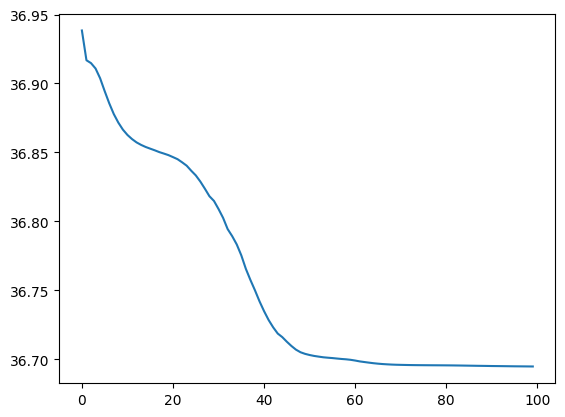

In [130]:
adult_path = "/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult.csv"
adult_data = pd.read_csv(adult_path)
n, d = adult_data.shape
Sigma_true = adult_data.cov().to_numpy()
Prec_true = np.linalg.inv(Sigma_true)
Sigma_tilde = get_Sigma_tilde_d15(Sigma_true, off_diagonal_percentage=0.15)
Prec_tilde = np.linalg.inv(Sigma_tilde)

print(f"Sigma_true, {Sigma_true}")
print(f"Prec_true, {Prec_true}")
print(f"Sigma_tilde, {Sigma_tilde}")
print(f"Prec_tilde, {Prec_tilde}")

z_init, inds_init = initialize_z(Sigma_tilde)
K_z_init = get_K(z_init, inds_init, d)
det_init = np.linalg.det(K_z_init)

z_opt = optimize_lbfgs(Sigma_tilde, z_init, inds_init, max_iters=100, verbose=False)
#z_opt = optimize_lbfgs_check(Sigma_tilde, z_init, max_iters=100, initial_step_size=1.0, step_size_reduction=0.5, min_step_size=1e-6)

In [121]:
K_z_opt = get_K(z_opt, inds_init, d)

print("Sigma_true", Sigma_true)
print("Prec_true", Prec_true)
print("\n")
print("Sigma_tilde", Sigma_tilde)
print("Prec_tilde", Prec_tilde)
print("\n")
print("Sigma_opt", np.linalg.inv(K_z_opt))
print("Prec_opt", K_z_opt)

Sigma_true [[ 2.65486314e+01  1.12558197e+00 -9.22363910e-01 -2.94606949e-01
   4.19322938e-01 -1.33256091e+00  6.63984134e-01  8.12983385e-01
  -1.76772016e-01  2.13452425e-01  8.55234974e-01  7.30598679e-01
   1.48889862e+00 -8.44349487e-01  5.04702921e-01]
 [ 1.12558197e+00  4.87413218e+00 -1.08345319e-01  2.01178630e-01
   2.87266037e-01  8.13887018e-02  4.15097129e+00 -8.85899371e-02
   1.03851217e-01 -5.56511224e-02 -2.39842511e-02  1.54525415e-02
  -1.02551966e+00 -5.54074570e-01 -8.47154464e-03]
 [-9.22363910e-01 -1.08345319e-01  5.23528579e+00 -1.99091992e-01
  -2.30920697e-01  6.76691231e-02 -3.58955702e-04  3.84921372e-02
   2.91511141e-01  2.89196964e-02 -1.75814372e-02 -2.84153292e-02
  -1.24947412e-01  1.21550142e+00 -6.78373232e-03]
 [-2.94606949e-01  2.01178630e-01 -1.99091992e-01  1.50116916e+01
   3.58272695e+00 -1.47761344e-01 -7.98710468e-02 -6.61787769e-02
  -1.32112502e-01 -4.93214012e-02  2.49767190e-01  1.70815448e-01
   8.88022310e-01 -2.39913304e+00  1.3239364